In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
# Load the dataset
df = pd.read_excel('BRA.xlsx')

contagem = df['Res'].value_counts().to_string()
print(f"{contagem}")
df['FTR'] = df['Res'].astype('string')
df['MaxCH'] = df['MaxCH'].astype('float')
df['MaxCA'] = df['MaxCA'].astype('float')
df['MaxCD'] = df['MaxCD'].astype('float')

hw = ((df['MaxCH'] < df['MaxCA']) & (df['FTR'] == 'H')).sum()
print(f"Odd acertada casa: {hw}")

aw = ((df['MaxCA'] < df['MaxCH']) & (df['FTR'] == 'A')).sum()
print(f"Odd acertada visitante: {aw}")

dw = ((df['MaxCD'] < df['MaxCH']) & (df['MaxCD'] < df['MaxCA']) & (df['FTR'] == 'D')).sum()
print(f"Odd acertada empate: {dw}")

odd_errou = ((df['MaxCH'] < df['MaxCA']) & (df['FTR'] == 'A')).sum() + ((df['MaxCA'] < df['MaxCH']) & (df['FTR'] == 'H')).sum() + ((df['MaxCD'] < df['MaxCH']) & (df['MaxCD'] < df['MaxCA']) & (df['FTR'] != 'D')).sum() + ((df['MaxCA'] < df['MaxCH']) & (df['FTR'] == 'D')).sum() + ((df['MaxCH'] < df['MaxCA']) & (df['FTR'] == 'D')).sum()
print(f"Odd erradas: {odd_errou}")



total = len(df)
print(f"Total de jogos: {total}")

hw_percent = (hw / total) * 100
aw_percent = (aw / total) * 100
dw_percent = (dw / total) * 100
erro_percent = (odd_errou / total) * 100
print(f"Odd acertada casa: {hw_percent:.2f}%")
print(f"Odd acertada visitante: {aw_percent:.2f}%")
print(f"Odd acertada empate: {dw_percent:.2f}%")
print(f"Odd erradas: {erro_percent:.2f}%")

Res
H    2601
D    1443
A    1321
Odd acertada casa: 2289
Odd acertada visitante: 460
Odd acertada empate: 2
Odd erradas: 2610
Total de jogos: 5366
Odd acertada casa: 42.66%
Odd acertada visitante: 8.57%
Odd acertada empate: 0.04%
Odd erradas: 48.64%


Text(0.5, 1.0, 'Porcentagem de Acertos das Odds (Brasil)')

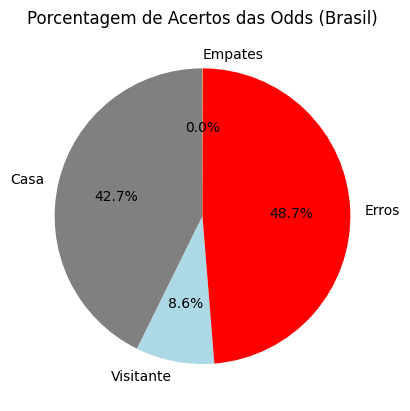

In [4]:
pizza = [hw_percent, aw_percent, erro_percent, dw_percent]
labels = ['Casa', 'Visitante', 'Erros', 'Empates']
plt.pie(pizza, labels=labels, autopct='%1.1f%%', startangle=90, colors=['gray', 'lightblue', 'red', 'orange'])
plt.title('Porcentagem de Acertos das Odds (Brasil)')